# Recognizing hand-written digits: scikit-learn vs Moxie (shared surface)

**Reference example:** `../scikit-learn/examples/classification/plot_digits_classification.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([gallery page](https://scikit-learn.org/dev/auto_examples/classification/plot_digits_classification.html)).

**Scenario:** the example loads the bundled digits dataset (`sklearn.datasets.load_digits`), fits
`svm.SVC(gamma=0.001)` on the first half (`train_test_split(test_size=0.5, shuffle=False)`), predicts the
second half and evaluates it with `sklearn.metrics.classification_report` and
`metrics.ConfusionMatrixDisplay.from_predictions`. It is the gallery's main tour of the cross-cutting
`sklearn.datasets` + `sklearn.metrics` surface, which is what this notebook verifies.

**Adaptations:**
- `load_digits` has no Moxie counterpart (no `moxie.datasets`); Python loads the bundled data and shares
  the `(1797, 64)` Float64 matrix and Int64 targets. Recorded as a GAP and proven by an `--expect-fail` cell.
- The split, the SVC fit/predict, `score` (the shared `ClassifierMixin` accuracy contract), `clone`
  and `check_is_fitted` run in Mojo. Labels are typed `Int` (`SVC[Int]`), the documented label-domain adaptation.
- `classification_report`, `confusion_matrix` and `ConfusionMatrixDisplay` have no Moxie counterpart
  (no `moxie.metrics`). The notebook evaluates Moxie's predictions with sklearn's metric functions in Python
  only to compare them; that step is recorded as a GAP and proven by an `--expect-fail` cell.

**Determinism:** fully deterministic. `shuffle=False`, and libsvm's SMO on this problem uses no RNG
(`probability=False`). Predictions and the accuracy are compared exactly.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("shared_surface/plot_digits_classification")

## 1. scikit-learn (Python reference)

The official example code, with figures kept small.

Classification report for classifier SVC(gamma=0.001):
              precision    recall  f1-score   support

           0       1.00      0.99      0.99        88
           1       0.99      0.97      0.98        91
           2       0.99      0.99      0.99        86
           3       0.98      0.87      0.92        91
           4       0.99      0.96      0.97        92
           5       0.95      0.97      0.96        91
           6       0.99      0.99      0.99        91
           7       0.96      0.99      0.97        89
           8       0.94      1.00      0.97        88
           9       0.93      0.98      0.95        92

    accuracy                           0.97       899
   macro avg       0.97      0.97      0.97       899
weighted avg       0.97      0.97      0.97       899


Confusion matrix:
[[87  0  0  0  1  0  0  0  0  0]
 [ 0 88  1  0  0  0  0  0  1  1]
 [ 0  0 85  1  0  0  0  0  0  0]
 [ 0  0  0 79  0  3  0  4  5  0]
 [ 0  0  0  0 88  0  0  0  0  4]
 [

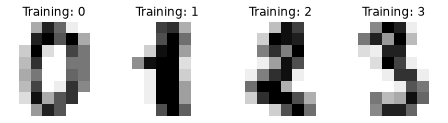

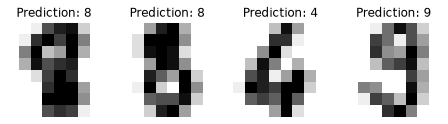

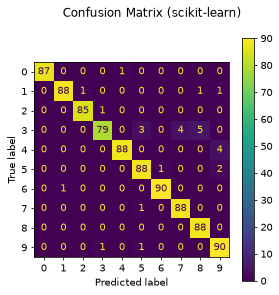

Classification report rebuilt from confusion matrix:
              precision    recall  f1-score   support

           0       1.00      0.99      0.99        88
           1       0.99      0.97      0.98        91
           2       0.99      0.99      0.99        86
           3       0.98      0.87      0.92        91
           4       0.99      0.96      0.97        92
           5       0.95      0.97      0.96        91
           6       0.99      0.99      0.99        91
           7       0.96      0.99      0.97        89
           8       0.94      1.00      0.97        88
           9       0.93      0.98      0.95        92

    accuracy                           0.97       899
   macro avg       0.97      0.97      0.97       899
weighted avg       0.97      0.97      0.97       899


sklearn score: 0.9688542825361512 | is_classifier: True | clone fitted: False


In [2]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn import datasets, metrics, svm
from sklearn.base import clone, is_classifier
from sklearn.model_selection import train_test_split

plt.rcParams["figure.dpi"] = 70
digits = datasets.load_digits()

_, axes = plt.subplots(nrows=1, ncols=4, figsize=(8, 2.4))
for ax, image, label in zip(axes, digits.images, digits.target):
    ax.set_axis_off()
    ax.imshow(image, cmap=plt.cm.gray_r, interpolation="nearest")
    ax.set_title("Training: %i" % label)

n_samples = len(digits.images)
data = digits.images.reshape((n_samples, -1))
clf = svm.SVC(gamma=0.001)
X_train, X_test, y_train, y_test = train_test_split(
    data, digits.target, test_size=0.5, shuffle=False
)
clf.fit(X_train, y_train)
predicted = clf.predict(X_test)

_, axes = plt.subplots(nrows=1, ncols=4, figsize=(8, 2.4))
for ax, image, prediction in zip(axes, X_test, predicted):
    ax.set_axis_off()
    image = image.reshape(8, 8)
    ax.imshow(image, cmap=plt.cm.gray_r, interpolation="nearest")
    ax.set_title(f"Prediction: {prediction}")

print(
    f"Classification report for classifier {clf}:\n"
    f"{metrics.classification_report(y_test, predicted)}\n"
)
disp = metrics.ConfusionMatrixDisplay.from_predictions(y_test, predicted)
disp.figure_.set_size_inches(4.5, 4.5)
disp.figure_.suptitle("Confusion Matrix (scikit-learn)")
print(f"Confusion matrix:\n{disp.confusion_matrix}")
plt.show()

y_true = []
y_pred = []
cm = disp.confusion_matrix
for gt in range(len(cm)):
    for pred in range(len(cm)):
        y_true += [gt] * cm[gt][pred]
        y_pred += [pred] * cm[gt][pred]
print(
    "Classification report rebuilt from confusion matrix:\n"
    f"{metrics.classification_report(y_true, y_pred)}\n"
)

# Shared-surface quantities the Moxie cell reproduces.
sk_score = clf.score(X_test, y_test)
fresh = clone(clf)
print("sklearn score:", sk_score, "| is_classifier:", is_classifier(clf),
      "| clone fitted:", hasattr(fresh, "support_"))
nb.share(data=data, target=digits.target.astype(np.int64))

## 2. Moxie (native Mojo)

The split, fit, prediction, accuracy, clone and fitted-state checks run in Mojo. The cell also refits
the clone with changed parameters and then restores them, checking that `set_params` + refit replaces the
learned state.

In [3]:
%%mojo digits_svc
import numojo as nm
from moxie.base import clone
from moxie.model_selection import SplitSize, train_test_split
from moxie.svm import SVC, Gamma
from moxie.utils import check_is_fitted
from moxie_nb_io import load, save, save_ints, save_floats


def as_labels(y: nm.NDArray[DType.int64]) raises -> List[Int]:
    var out = List[Int]()
    for i in range(y.size):
        out.append(Int(y.load(i)))
    return out^


def main() raises:
    var data = load("data")
    var target = load[DType.int64]("target")
    var split = train_test_split(data, target, test_size=SplitSize(0.5), shuffle=False)
    var X_train = split[0].copy()
    var X_test = split[1].copy()
    var y_train = as_labels(split[2])
    var y_test = as_labels(split[3])
    save_ints("y_test", y_test)

    var clf = SVC[Int](gamma=0.001)
    var fresh = clone(clf)
    _ = clf.fit(X_train, y_train)
    var predicted = clf.predict(X_test)
    save_ints("predicted", predicted)
    save_floats("score", [clf.score(X_test, y_test)])
    save("n_support", clf.n_support_)
    save("support", clf.support_)
    save("dual_coef", clf.dual_coef_)
    save("intercept", clf.intercept_)

    # Clone is unfitted and fails clearly before fit; check_is_fitted passes on the fitted original.
    check_is_fitted(clf)
    try:
        check_is_fitted(fresh)
        print("clone unexpectedly fitted")
    except e:
        print("clone before fit:", e)
    try:
        _ = fresh.predict(X_test)
        print("clone unexpectedly predicted")
    except e:
        print("clone predict before fit:", e)

    # set_params then refit replaces learned state; restoring gamma reproduces the original fit.
    _ = fresh.set_params(gamma=Gamma(0.01)).fit(X_train, y_train)
    save_floats("score_gamma_0_01", [fresh.score(X_test, y_test)])
    _ = fresh.set_params(gamma=Gamma(0.001)).fit(X_train, y_train)
    save_ints("refit_predicted", fresh.predict(X_test))
    print("moxie score:", clf.score(X_test, y_test))

clone before fit: NotFittedError: call fit before inference
clone predict before fit: NotFittedError: estimator is not fitted
moxie score: 0.9688542825361512


## 3. Side by side and parity

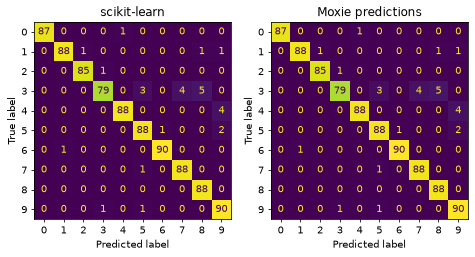

True

In [4]:
mx = nb.results["digits_svc"]
mx_pred = np.asarray(mx["predicted"])
cm_moxie = metrics.confusion_matrix(y_test, mx_pred)  # evaluation only: no moxie.metrics
moxie_nb.side_by_side(sklearn=cm, moxie=cm_moxie)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
metrics.ConfusionMatrixDisplay(cm).plot(ax=axes[0], colorbar=False)
axes[0].set_title("scikit-learn")
metrics.ConfusionMatrixDisplay(cm_moxie).plot(ax=axes[1], colorbar=False)
axes[1].set_title("Moxie predictions")
plt.show()

nb.compare("y_test (split, shuffle=False)", y_test, mx["y_test"], exact=True)
nb.compare("predict", predicted, mx_pred, exact=True)
nb.compare("score (ClassifierMixin accuracy)", sk_score, mx["score"][0], exact=True)
nb.compare("n_support_", clf.n_support_, mx["n_support"], exact=True)
nb.compare("support_", clf.support_, mx["support"], exact=True)
nb.compare("dual_coef_", clf.dual_coef_, mx["dual_coef"], rtol=1e-6, atol=1e-8,
           reason="same libsvm SMO in Float64; the stopping tolerance tol=1e-3 bounds how far two "
                  "implementations' iterates may legitimately drift, observed agreement is far tighter")
nb.compare("intercept_", clf.intercept_, mx["intercept"], rtol=1e-6, atol=1e-8,
           reason="derived from the dual solution above, same tolerance argument")
sk_g = clone(clf).set_params(gamma=0.01).fit(X_train, y_train).score(X_test, y_test)
nb.compare("set_params(gamma=0.01) + refit score", sk_g, mx["score_gamma_0_01"][0], exact=True)
nb.compare("clone refit restores predictions", predicted, mx["refit_predicted"], exact=True)
nb.compare("confusion_matrix of predictions", cm, cm_moxie, exact=True)

## 4. Steps Moxie cannot do

`moxie.datasets` and `moxie.metrics` do not exist. The cells below prove the failures are clear compile
errors, not silent substitutes.

In [5]:
%%mojo no_datasets --expect-fail
from moxie.datasets import load_digits


def main() raises:
    var digits = load_digits()

Expected failure (unsupported in Moxie):
compilation failed
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/notebooks/shared_surface/plot_digits_classification/no_datasets.mojo:1:12: error: unable to locate module 'datasets'
from moxie.datasets import load_digits
           ^
mojo: error: failed to parse the provided Mojo source module



In [6]:
%%mojo no_metrics --expect-fail
from moxie.metrics import classification_report, confusion_matrix


def main() raises:
    print(confusion_matrix([0, 1], [0, 1]))

Expected failure (unsupported in Moxie):
compilation failed
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/notebooks/shared_surface/plot_digits_classification/no_metrics.mojo:1:12: error: unable to locate module 'metrics'
from moxie.metrics import classification_report, confusion_matrix
           ^
mojo: error: failed to parse the provided Mojo source module



In [7]:
nb.note("load_digits", "GAP", "no moxie.datasets: bundled loaders and generators are absent; Python shares the data")
nb.note("classification_report / confusion_matrix", "GAP",
        "no moxie.metrics: classification metrics are absent; estimator score() is the only native accuracy")
nb.note("ConfusionMatrixDisplay", "GAP", "no metrics display objects; plotting uses sklearn on Moxie predictions")
nb.note("labels", "ADAPTED", "typed SVC[Int] labels and List[Int] targets instead of a NumPy integer array")
nb.note("train_test_split(test_size=0.5)", "ADAPTED", "the fraction is passed as SplitSize(0.5): typed split sizes")
nb.report()
nb.assert_parity()

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
"y_test (split, shuffle=False)",PASS,"(899,)","(899,)",,,exact,0 mismatches,
predict,PASS,"(899,)","(899,)",,,exact,0 mismatches,
score (ClassifierMixin accuracy),PASS,(),(),,,exact,0 mismatches,
n_support_,PASS,"(10,)","(10,)",,,exact,0 mismatches,
support_,PASS,"(519,)","(519,)",,,exact,0 mismatches,
dual_coef_,PASS,"(9, 519)","(9, 519)",0,0,"rtol=1e-06, atol=1e-08",,"same libsvm SMO in Float64; the stopping tolerance tol=1e-3 bounds how far two implementations' iterates may legitimately drift, observed agreement is far tighter"
intercept_,PASS,"(45,)","(45,)",0,0,"rtol=1e-06, atol=1e-08",,"derived from the dual solution above, same tolerance argument"
set_params(gamma=0.01) + refit score,PASS,(),(),,,exact,0 mismatches,
clone refit restores predictions,PASS,"(899,)","(899,)",,,exact,0 mismatches,
confusion_matrix of predictions,PASS,"(10, 10)","(10, 10)",,,exact,0 mismatches,
